# Línea base · Clasificación de daños en vehículos con CLIP sin entrenar
### IA Generativa para la Gestión Industrial · Certamen 1

**Objetivo:** medir qué tan bien clasifica los 6 tipos de daño un modelo preentrenado **sin entrenarlo con nuestros datos** (CLIP *zero-shot*). Este resultado es la **línea base** contra la que se compara EfficientNet: si el modelo entrenado no la supera claramente, entrenar no vale la pena.

📷 Recorte del daño → 🧠 CLIP compara la imagen con una frase por clase → 📊 Clase más parecida → ✅ Métricas en prueba



In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


## 1. Los datos
Usamos los **recortes de CarDD** generados por el grupo: cada recorte muestra un solo daño y está en la carpeta de su clase (`test/<clase>/`). Solo usamos el conjunto de **prueba**, el mismo con el que se evalúa EfficientNet.

Copiamos el zip desde Drive al disco de Colab antes de descomprimirlo, porque leer miles de archivos directamente desde Drive falla de forma intermitente.

In [2]:
import shutil

shutil.copy("/content/drive/MyDrive/crops_cardd.zip", "/content/crops_cardd.zip")
shutil.unpack_archive("/content/crops_cardd.zip", "/content/crops")

In [3]:
import os

DATOS = "/content/crops"
CLASES = sorted(os.listdir(f"{DATOS}/test"))
for c in CLASES:
    print(f"{c:15s} test = {len(os.listdir(f'{DATOS}/test/{c}'))}")

crack           test = 54
dent            test = 234
glass_shatter   test = 71
lamp_broken     test = 69
scratch         test = 298
tire_flat       test = 32


 El conjunto de prueba tiene **758 recortes** con un desbalance fuerte: `scratch` tiene 298 y `tire_flat` solo 32. Un modelo que respondiera siempre *scratch* sin mirar la foto acertaría 298 / 758 = **39,3 %**. Ese es el piso real de la accuracy, no el 16,7 % del azar con 6 clases.

Por eso usamos **accuracy balanceada** (promedio del acierto de cada clase): cada clase pesa lo mismo, y fallar en una clase pequeña se nota.

**Evaluación común.** Para comparar modelos en igualdad de condiciones, todos se prueban con las **mismas 758 imágenes** y la **misma métrica**. Cada modelo solo debe aportar una función `predecir(ruta) → clase`.

In [4]:
from sklearn.metrics import balanced_accuracy_score    # métrica que promedia el acierto de cada clase

prueba = [(f"{DATOS}/test/{c}/{a}", c)                 # lista de (ruta de la imagen, clase real)
          for c in CLASES
          for a in os.listdir(f"{DATOS}/test/{c}")]
RESULTADOS = {}                                        # guarda el puntaje de cada modelo

def evaluar(nombre, predecir):                         # evalúa un modelo sobre el conjunto de prueba
    reales = [c for _, c in prueba]                    # clases verdaderas
    preds  = [predecir(r) for r, _ in prueba]          # clases predichas por el modelo
    RESULTADOS[nombre] = balanced_accuracy_score(reales, preds)
    print(f"{nombre}: accuracy balanceada = {RESULTADOS[nombre]:.1%}")
    return reales, preds                               # se usan después para la matriz de confusión

print("Imágenes de prueba:", len(prueba))

Imágenes de prueba: 758


## 2. CLIP sin entrenar (*zero-shot*)
CLIP fue entrenado con millones de pares imagen-texto de internet. No conoce nuestras clases: compara la imagen con **una frase por clase** escrita por nosotros (en inglés, el idioma en que aprendió) y elige la más parecida.

In [5]:
import torch
from transformers import pipeline

GPU = 0 if torch.cuda.is_available() else -1           # usa la GPU si está disponible

clip = pipeline("zero-shot-image-classification",      # CLIP sin entrenar (zero-shot)
                model="openai/clip-vit-base-patch32", device=GPU)

TEXTOS = {                                             # una frase en inglés por clase
    "crack":         "a photo of a crack in a car bumper",
    "dent":          "a photo of a dent in a car body",
    "glass_shatter": "a photo of a shattered car window",
    "lamp_broken":   "a photo of a broken car headlight",
    "scratch":       "a photo of a scratch on car paint",
    "tire_flat":     "a photo of a flat car tire",
}
A_CLASE = {v: k for k, v in TEXTOS.items()}            # traduce frase → clase

def predecir_clip(ruta):                               # devuelve la clase más parecida a la imagen
    return A_CLASE[clip(ruta, candidate_labels=list(TEXTOS.values()))[0]["label"]]

config.json:   0%|          | 0.00/4.19k [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  605MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/592 [00:00<?, ?B/s]

...

vocab.json:   0%|          | 0.00/862k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/525k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/2.22M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/389 [00:00<?, ?B/s]

preprocessor_config.json:   0%|          | 0.00/316 [00:00<?, ?B/s]

In [6]:
reales, preds_clip = evaluar("1 · CLIP (sin entrenar)", predecir_clip)   # evalúa CLIP en el conjunto de prueba

[transformers] You seem to be using the pipelines sequentially on GPU. In order to maximize efficiency please use a dataset


1 · CLIP (sin entrenar): accuracy balanceada = 73.5%


**Análisis;** CLIP obtuvo **73,5 % de accuracy balanceada** sin haber visto nunca nuestros datos, muy por encima del azar (16,7 %). Es lo contrario de lo que ocurrió con las resonancias de Alzheimer (Pauta 2), donde quedó cerca del azar: CLIP aprendió de fotos de internet, donde abundan imágenes de autos, neumáticos y parabrisas, pero casi no hay resonancias cerebrales.

## 3. Métricas en prueba y matriz de confusión
- **Precision:** de lo que el modelo llamó X, cuánto era realmente X (pocas falsas alarmas).
- **Recall:** de lo que era X, cuánto detectó el modelo (pocos daños que se escapan).
- **Matriz de confusión:** filas = clase real, columnas = clase predicha. La diagonal son los aciertos.

               precision    recall  f1-score   support

        crack      0.183     0.833     0.300        54
         dent      0.639     0.453     0.530       234
glass_shatter      0.769     0.986     0.864        71
  lamp_broken      0.770     0.826     0.797        69
      scratch      0.730     0.309     0.434       298
    tire_flat      0.582     1.000     0.736        32

     accuracy                          0.530       758
    macro avg      0.612     0.735     0.610       758
 weighted avg      0.664     0.530     0.540       758



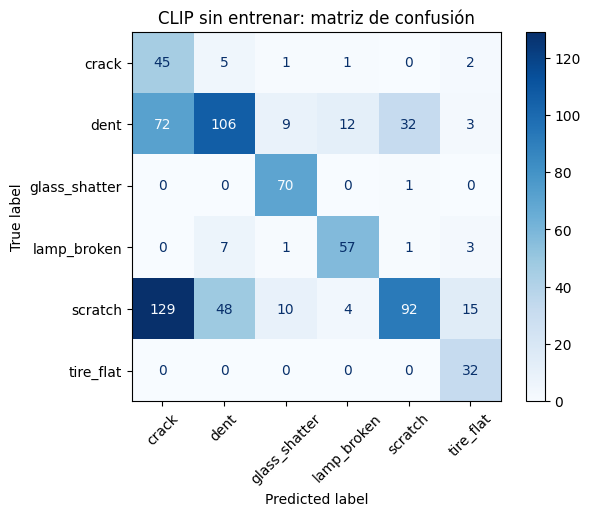

In [7]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report  # métricas de evaluación
import matplotlib.pyplot as plt                                                               # gráficos

print(classification_report(reales, preds_clip, labels=CLASES, digits=3))   # precision, recall y f1 por clase

ConfusionMatrixDisplay(confusion_matrix(reales, preds_clip, labels=CLASES),  # matriz de confusión
                       display_labels=CLASES).plot(cmap="Blues", xticks_rotation=45)
plt.title("CLIP sin entrenar: matriz de confusión"); plt.show()

**Análisis de resultados**

1. **Accuracy (53,0 %) vs. accuracy balanceada (73,5 %).** La accuracy apenas supera en 14 puntos al modelo que siempre dice *scratch* (39,3 %). La balanceada es mucho mayor porque CLIP acierta en las clases pequeñas y falla en las grandes.

2. **Dónde le va bien y dónde mal.** Reconoce muy bien los daños sobre objetos fáciles de identificar: `tire_flat` (recall 100 %), `glass_shatter` (98,6 %), `lamp_broken` (82,6 %). Falla en los daños sutiles de carrocería: `scratch` (30,9 %) y `dent` (45,3 %), que son justamente las clases más frecuentes.

3. **Error más frecuente.** Confunde rayones y abolladuras con grietas: predijo *crack* en 129 rayones y 72 abolladuras. Por eso la precision de `crack` es solo 18,3 %: de cada 10 veces que dice "grieta", más de 8 se equivoca.

4. **Error más costoso.** Lo más grave es subestimar un daño (clasificar como `dent` o `scratch` una grieta, un vidrio roto, un foco roto o un neumático pinchado), porque lleva a cotizar de menos o a liberar un vehículo inseguro. CLIP lo comete en **14 de 226 daños graves (6,2 %)**. Su problema es el contrario: **sobrestima** los daños leves, lo que genera falsas alarmas y revisiones innecesarias.

**Conclusión.** Un modelo general reconoce los daños evidentes, pero no distingue con fiabilidad los daños sutiles de carrocería, que son la mayoría de los casos reales. Hay que adaptarlo con datos del dominio (EfficientNet), que debe superar este **73,5 % de accuracy balanceada** para justificar el entrenamiento.